# 01 · Exploratory data analysis
IBM Telco Customer Churn (primary dataset). Observed fields vs engineered proxies are listed in `reports/feature_dictionary.csv`.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Image
from src import config
pd.set_option('display.width', 160); sns.set_theme(style='whitegrid')
from src.ingestion import load_raw_excel, validate, bank_dataset_summary
raw = load_raw_excel(); rep = validate(raw)
print(rep.to_dict()); print(bank_dataset_summary())

{'n_rows': 7043, 'n_columns': 33, 'duplicate_customer_ids': 0, 'duplicate_rows': 0, 'missing_by_column': {'churn_reason': 5174}, 'blank_total_charges': 11, 'blank_total_charges_all_zero_tenure': True, 'invalid_categories': {}, 'range_violations': {}, 'churn_label_value_mismatch': 0, 'total_charges_inconsistent_gt_50pct': 2, 'churn_rate': 0.2653698707936959, 'errors': [], 'warnings': ['11 blank Total Charges (all tenure=0: True); imputed as 0.0', '2 rows where total_charges differs >50% from tenure*monthly (plausible: plan changes over time); kept as observed.'], 'passed': True}
{'rows': 10000, 'columns': ['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited'], 'churn_rate': 0.2037, 'has_tenure_years_only': True, 'has_monthly_charges': False}


The bank dataset was inspected only: it has annual tenure and no billing amounts, so it cannot support the subscription-revenue analyses (CLV, ROI). Telco is used.

In [2]:
df = pd.read_csv(config.DATA_PROCESSED / 'customers_processed.csv')   # cleaned + engineered (written by ingestion)
print(df.shape, 'churn rate', round(df.churn.mean(),4))
display(df[['tenure_months','monthly_charges','total_charges']].describe().round(2))

(7043, 49) churn rate 0.2654


,tenure_months,monthly_charges,total_charges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [3]:
from src import eda
s = eda.run_eda(df)
for k in ['churn_by_contract','churn_by_payment','churn_by_internet','churn_by_tenure_group']: print(k, s[k])

churn_by_contract {'Month-to-month': 0.4271, 'One year': 0.1127, 'Two year': 0.0283}
churn_by_payment {'Bank transfer (automatic)': 0.1671, 'Credit card (automatic)': 0.1524, 'Electronic check': 0.4529, 'Mailed check': 0.1911}
churn_by_internet {'DSL': 0.1896, 'Fiber optic': 0.4189, 'No': 0.074}
churn_by_tenure_group {'0-12m': 0.4744, '13-24m': 0.2871, '25-48m': 0.2039, '49-72m': 0.0951}


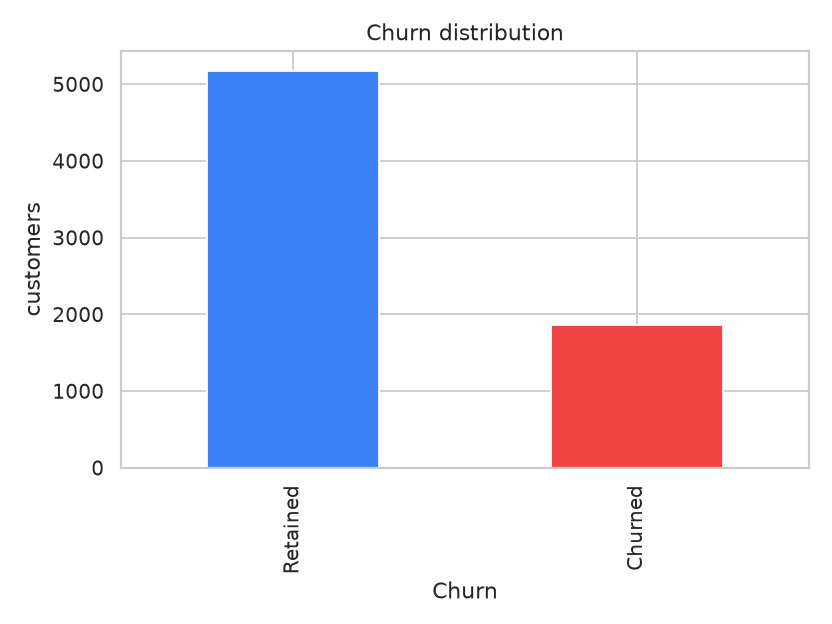

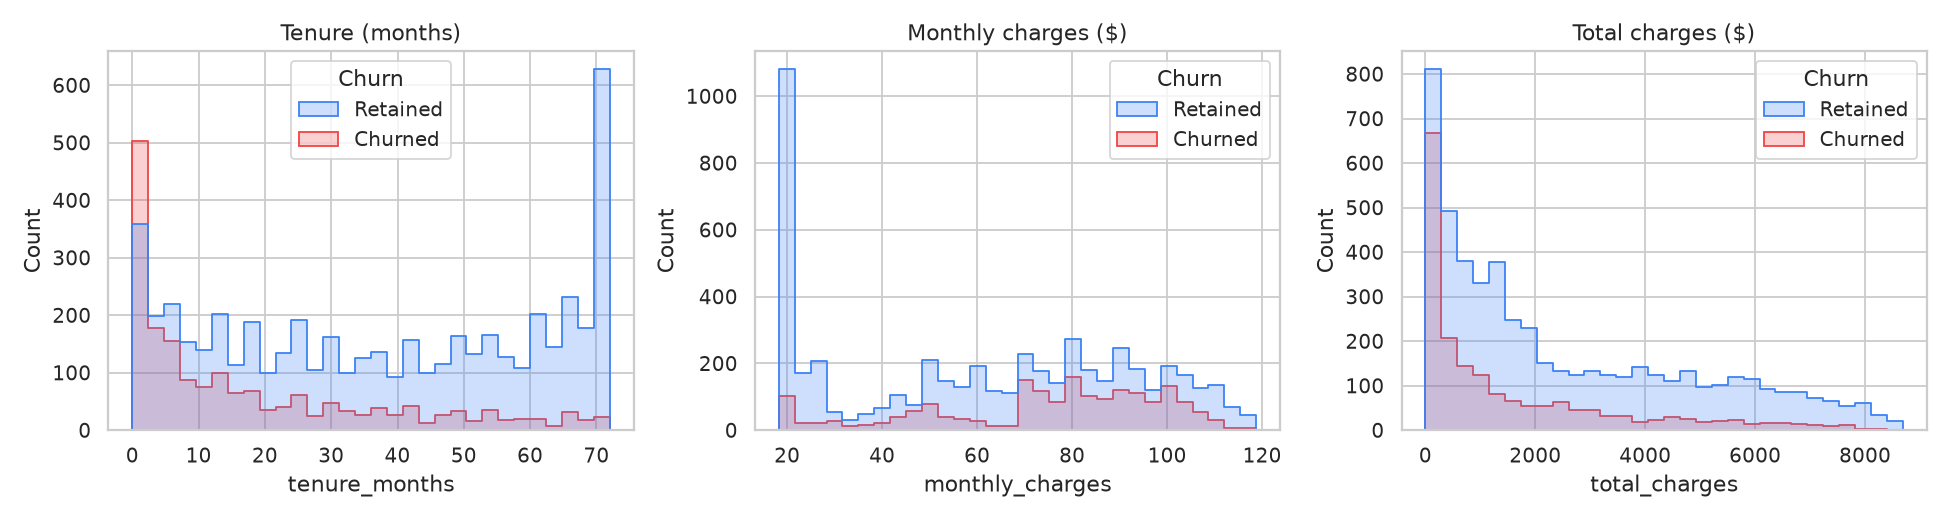

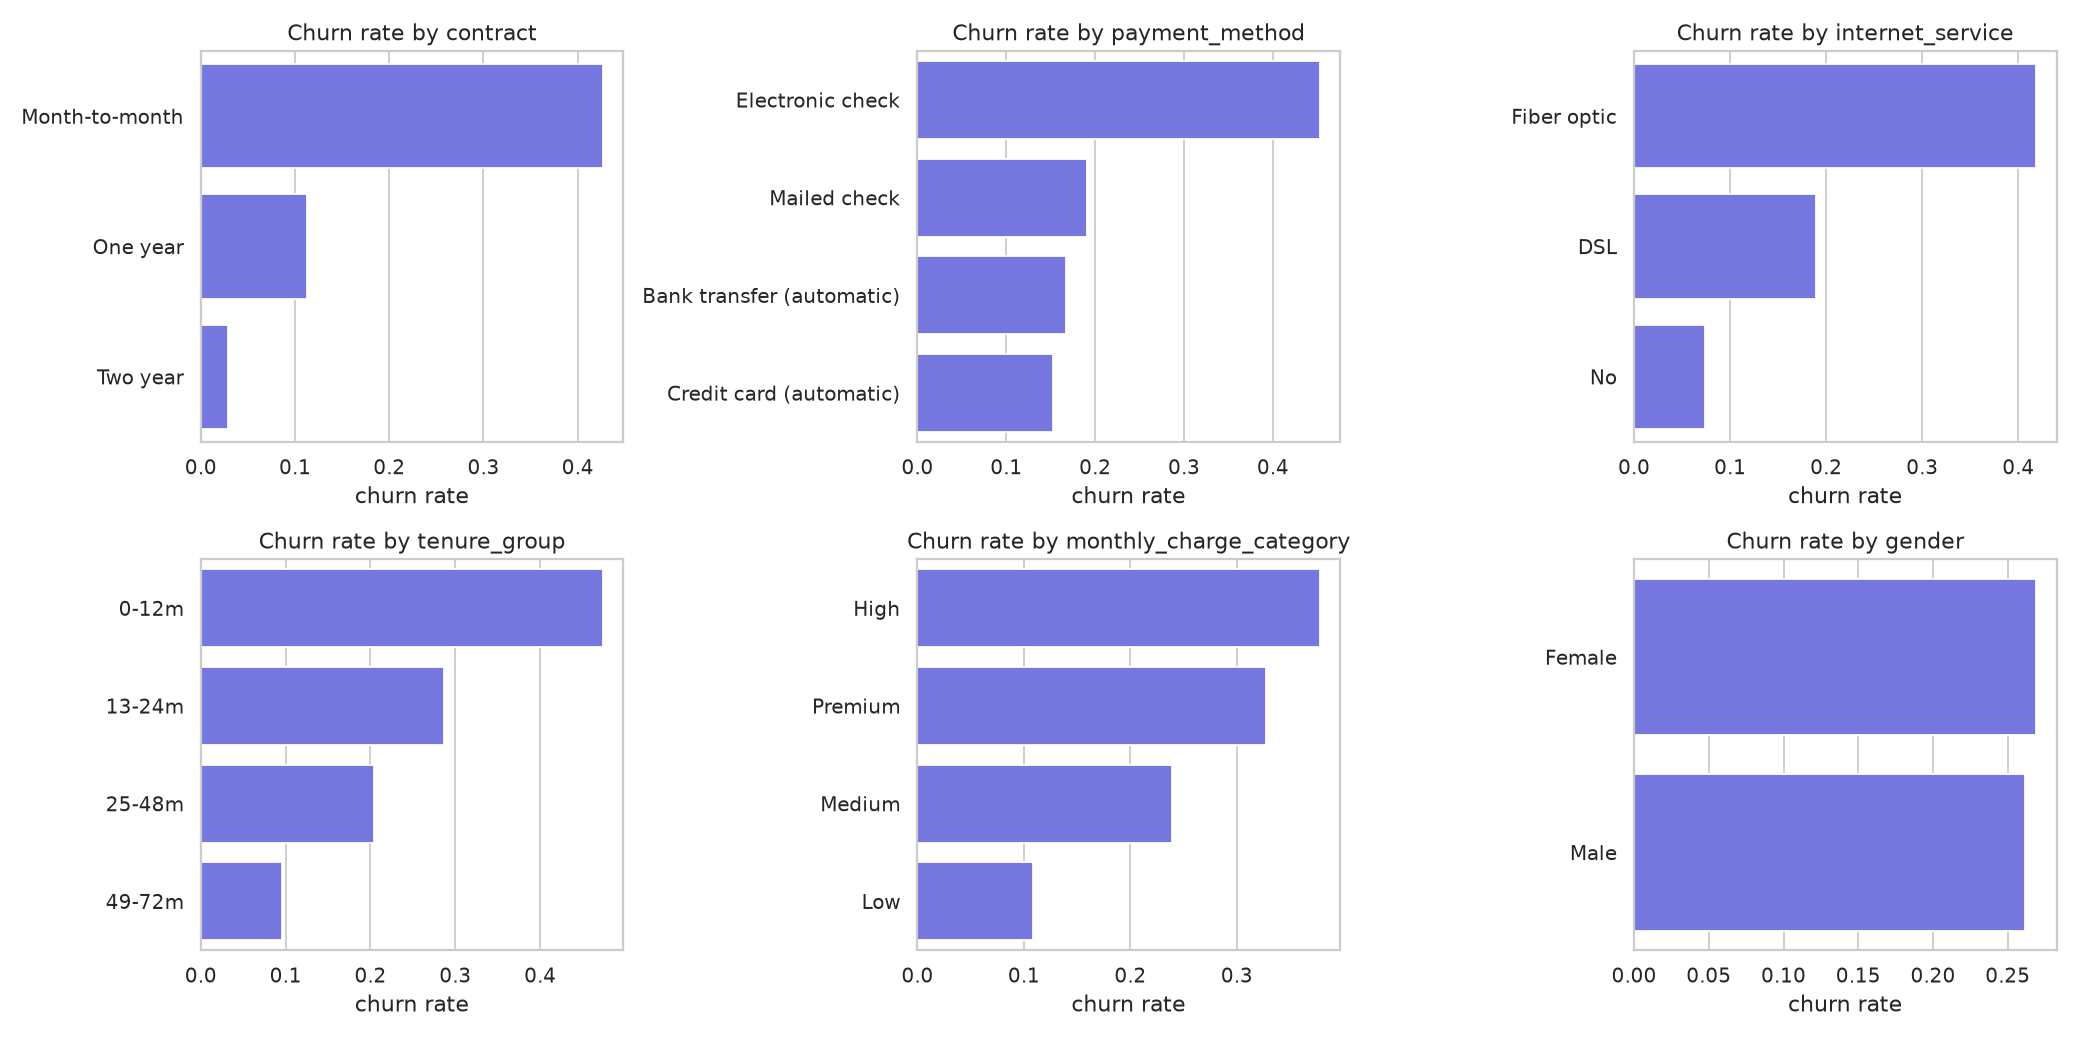

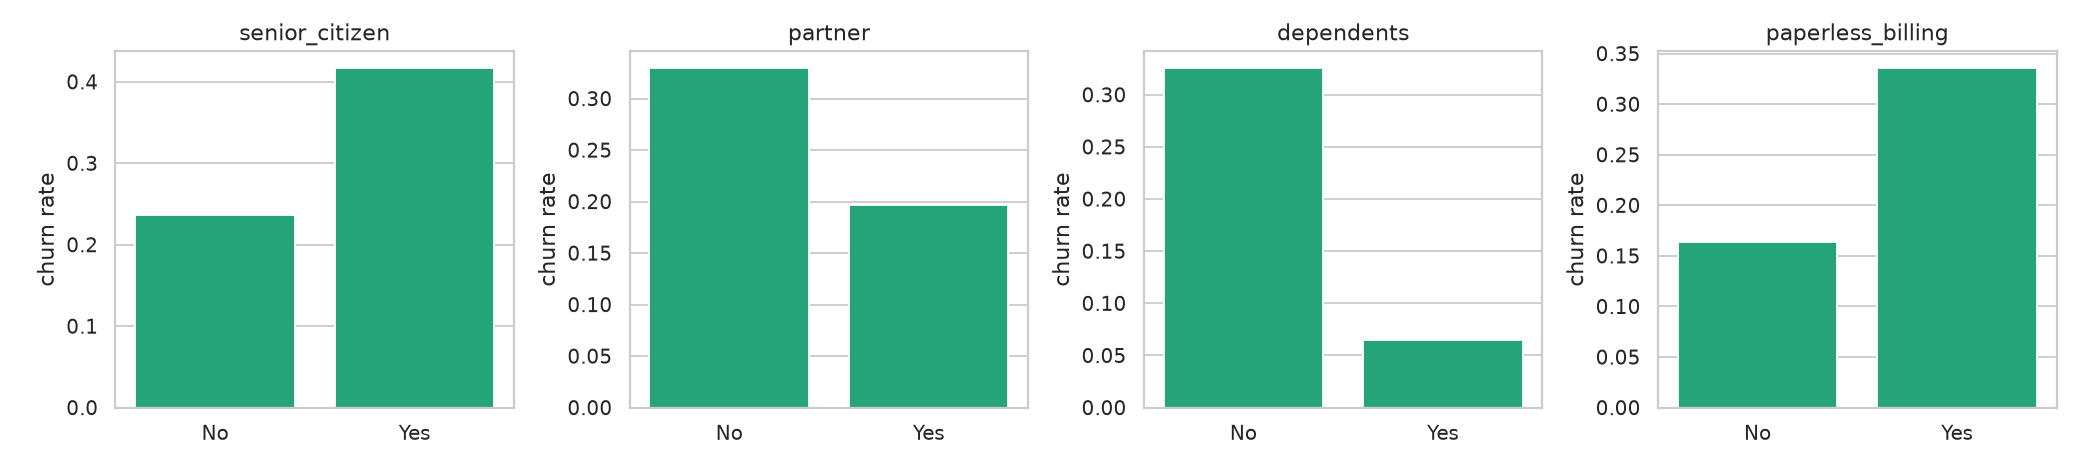

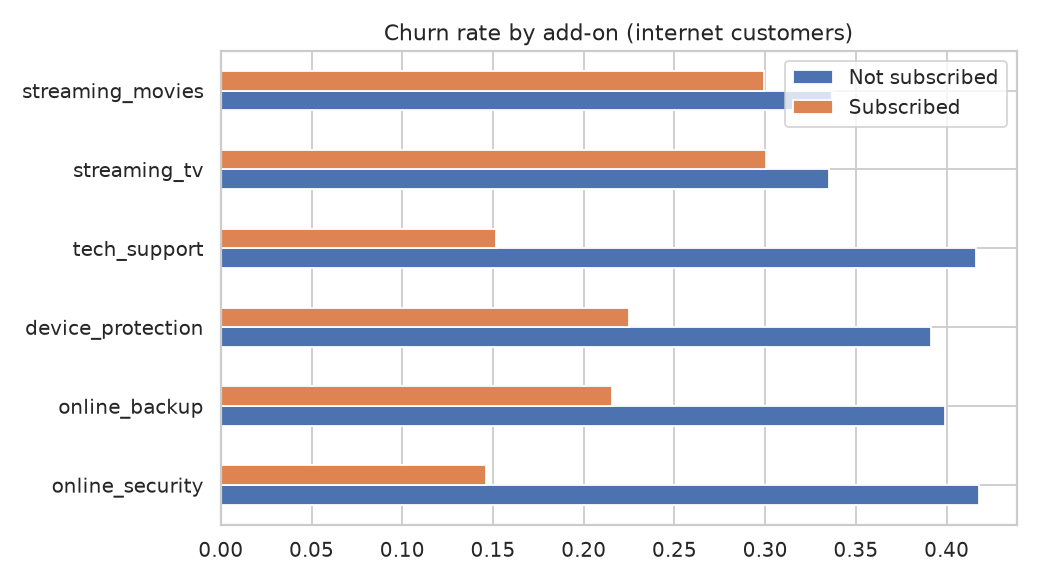

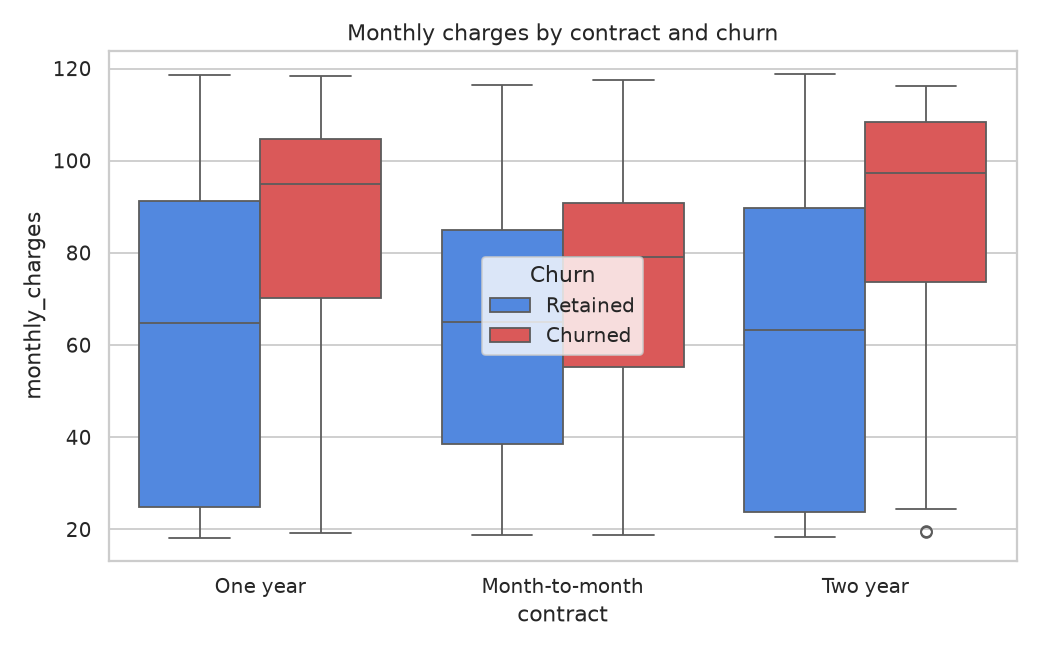

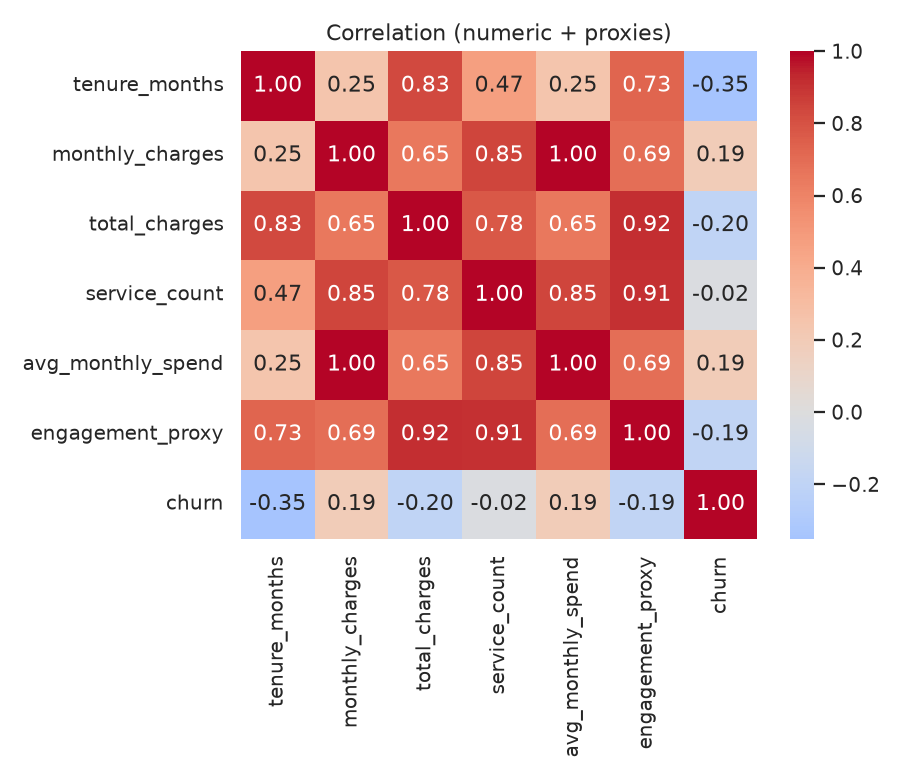

In [4]:
for f in ['eda_churn_distribution','eda_numeric_distributions','eda_churn_rate_by_category','eda_demographics','eda_addons','eda_charges_by_contract','eda_correlation']:
    display(Image(str(config.FIGURES_DIR / (f + '.png'))))

**Reading:** churn concentrates in month-to-month contracts, fiber-optic internet, electronic-check payers and the first year of tenure. These are associations in a single snapshot, not causal effects.